# Final Assignment: Analisis Regresi Harga Rumah di Ames, Iowa

Course 2: Supervised Learning (Regression)

Laporan ini mengikuti lima bagian penilaian: deskripsi dataset, tujuan analisis, perbandingan model, temuan dan interpretasi, serta evaluasi dan langkah selanjutnya. Angka-angka di bagian kesimpulan dihitung otomatis dari hasil model di notebook ini, jadi selalu sesuai dengan output yang tampil.

## Persiapan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style("whitegrid")

## 1. Deskripsi Dataset

**Sumber.** Dataset Ames Housing disusun oleh Dean De Cock (2011) sebagai alternatif modern dari dataset Boston Housing untuk keperluan pendidikan, dan dipakai luas di kompetisi Kaggle "House Prices: Advanced Regression Techniques". File yang dipakai di sini adalah `Ames_Housing_Sales.csv` dari materi Coursera (IBM), versi yang sebagian nilai kosongnya sudah diisi. Isinya data penjualan rumah di kota Ames, Iowa, Amerika Serikat.

**Struktur.** Setiap baris adalah satu transaksi penjualan rumah. Kolom `SalePrice` adalah target (harga jual dalam dolar), sisanya adalah fitur yang menggambarkan rumah dan transaksinya, misalnya:

| Kolom | Keterangan |
| --- | --- |
| `SalePrice` | harga jual rumah (target) |
| `MSSubClass` | kelas bangunan |
| `MSZoning` | klasifikasi zonasi |
| `SaleType` | jenis penjualan |
| `SaleCondition` | kondisi penjualan |
| `MoSold`, `YrSold` | bulan dan tahun terjual |

Selain itu ada puluhan fitur tentang ukuran, kualitas, dan kondisi bangunan, lahan, garasi, dan lingkungan sekitarnya.

In [2]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/data/Ames_Housing_Sales.csv"
data = pd.read_csv(URL)

print("jumlah baris dan kolom:", data.shape)
print("kolom numerik         :", data.select_dtypes("number").shape[1])
print("kolom kategorikal     :", data.select_dtypes(exclude="number").shape[1])
print("total nilai kosong    :", int(data.isnull().sum().sum()))
data.head()

jumlah baris dan kolom: (1379, 80)
kolom numerik         : 37
kolom kategorikal     : 43
total nilai kosong    : 8657


,1stFlrSF,2ndFlrSF,3SsnPorch,Alley,BedroomAbvGr,BldgType,BsmtCond,BsmtExposure,BsmtFinSF1,BsmtFinSF2,...,ScreenPorch,Street,TotRmsAbvGrd,TotalBsmtSF,Utilities,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold,SalePrice
0,856.0,854.0,0.0,NaN,3,1Fam,TA,No,706.0,0.0,...,0.0,Pave,8,856.0,AllPub,0.0,2003,2003,2008,208500.0
1,1262.0,0.0,0.0,NaN,3,1Fam,TA,Gd,978.0,0.0,...,0.0,Pave,6,1262.0,AllPub,298.0,1976,1976,2007,181500.0
2,920.0,866.0,0.0,NaN,3,1Fam,TA,Mn,486.0,0.0,...,0.0,Pave,6,920.0,AllPub,0.0,2001,2002,2008,223500.0
3,961.0,756.0,0.0,NaN,3,1Fam,Gd,No,216.0,0.0,...,0.0,Pave,7,756.0,AllPub,0.0,1915,1970,2006,140000.0
4,1145.0,1053.0,0.0,NaN,4,1Fam,TA,Av,655.0,0.0,...,0.0,Pave,9,1145.0,AllPub,192.0,2000,2000,2008,250000.0


In [3]:
data["SalePrice"].describe().round(0)

,SalePrice
count,1379.0
mean,185480.0
std,79024.0
min,35311.0
25%,134000.0
50%,167500.0
75%,217750.0
max,755000.0


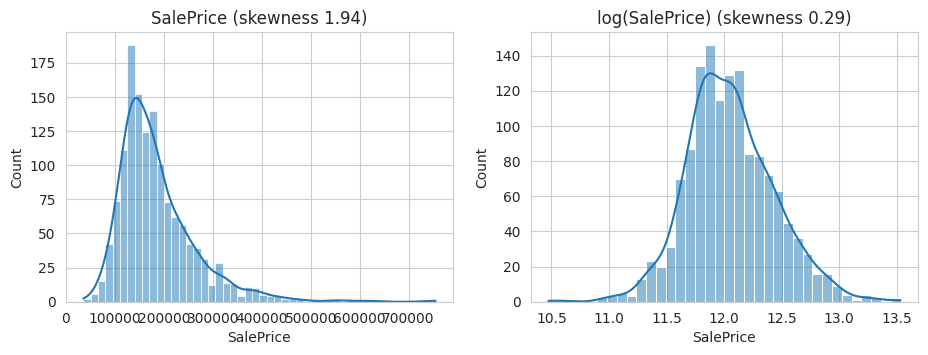

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(data["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title(f"SalePrice (skewness {data['SalePrice'].skew():.2f})")
sns.histplot(np.log(data["SalePrice"]), kde=True, ax=axes[1])
axes[1].set_title(f"log(SalePrice) (skewness {np.log(data['SalePrice']).skew():.2f})")
plt.show()

Distribusi harga miring ke kanan: sebagian besar rumah berharga menengah, sementara sedikit rumah sangat mahal membuat ekor panjang. Ini penting karena kesalahan prediksi di rumah mahal akan cenderung lebih besar.

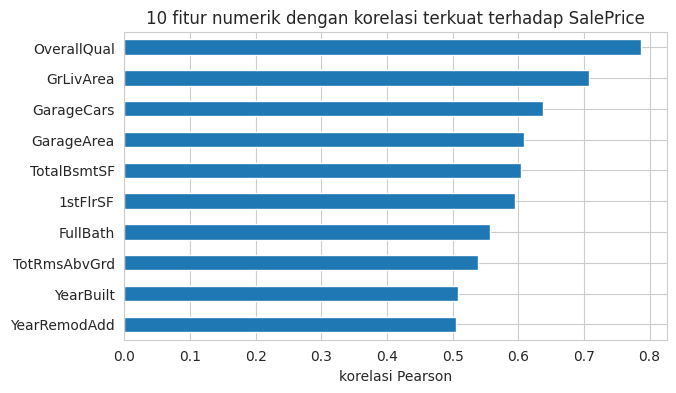

In [5]:
angka = data.select_dtypes("number")
korelasi = angka.corr()["SalePrice"].drop("SalePrice").sort_values(key=abs, ascending=False)

korelasi.head(10).sort_values().plot.barh(figsize=(7, 4))
plt.title("10 fitur numerik dengan korelasi terkuat terhadap SalePrice")
plt.xlabel("korelasi Pearson")
plt.show()

## 2. Tujuan Analisis

**Masalah.** Harga rumah bergantung pada banyak faktor sekaligus. Penjual, pembeli, atau penilai properti butuh perkiraan harga yang masuk akal berdasarkan karakteristik rumah.

**Tujuan.** Analisis ini punya dua tujuan:

1. **Prediksi:** membangun model regresi linear yang memprediksi `SalePrice` dengan error sekecil mungkin pada rumah yang belum pernah dilihat model.
2. **Interpretasi:** mengetahui fitur mana yang paling berpengaruh terhadap harga dan ke arah mana pengaruhnya.

**Ukuran keberhasilan.** Model dinilai dengan RMSE (rata-rata besar kesalahan dalam dolar) dan $R^2$ pada data test yang disisihkan sejak awal. Pemilihan model dan hyperparameter dilakukan lewat cross validation di data train saja, sehingga data test baru dipakai di akhir.

## 3. Perbandingan Model

### Persiapan data modeling

Langkahnya: one-hot encode kolom kategorikal, bagi data 70% train dan 30% test, lalu transformasi log1p pada fitur float yang miring (skewness lebih dari 0.75, dihitung dari data train). `SalePrice` tidak ditransformasi di sini.

In [6]:
ames = pd.get_dummies(data, drop_first=True, dtype=int)
print("setelah one-hot:", ames.shape)

train, test = train_test_split(ames, test_size=0.3, random_state=42)
train, test = train.copy(), test.copy()

kolom_float = ames.select_dtypes("float").columns.drop("SalePrice")
skew = train[kolom_float].skew()
kolom_miring = skew[skew.abs() > 0.75].index
train[kolom_miring] = np.log1p(train[kolom_miring])
test[kolom_miring] = np.log1p(test[kolom_miring])
print(len(kolom_miring), "fitur float ditransformasi log1p")

fitur = [c for c in train.columns if c != "SalePrice"]
X_train, y_train = train[fitur], train["SalePrice"]
X_test, y_test = test[fitur], test["SalePrice"]
print("train:", X_train.shape, "| test:", X_test.shape)

setelah one-hot: (1379, 241)
19 fitur float ditransformasi log1p
train: (965, 240) | test: (414, 240)


### Model yang dibandingkan

Semua model adalah model linear dan semuanya dibungkus `Pipeline` bersama `StandardScaler`, supaya scaling hanya belajar dari data latih di setiap lipatan cross validation.

1. **Regresi linear** biasa sebagai pembanding dasar.
2. **Regresi polinomial derajat 2** pada 5 fitur numerik berkorelasi terkuat (fitur lain dipakai apa adanya). Polinomial tidak dipasang ke semua fitur karena jumlah fiturnya akan meledak.
3. **Ridge** (penalti L2), alpha dicari dengan `GridSearchCV`.
4. **Lasso** (penalti L1, bisa menyeleksi fitur), alpha dicari dengan `GridSearchCV`.
5. **Elastic Net** (gabungan L1 dan L2), alpha dan `l1_ratio` dicari dengan `GridSearchCV`.
6. **Ridge dengan target di-log**: model dilatih pada log harga, lalu prediksi dikembalikan ke dolar. Ini untuk menguji apakah miringnya distribusi harga mengganggu.

In [7]:
def bungkus(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

# 5 fitur numerik dengan korelasi terkuat (dihitung dari data train)
kolom_numerik_asli = data.select_dtypes("number").columns.drop("SalePrice")
kolom_poly = (train[kolom_numerik_asli].corrwith(train["SalePrice"])
              .abs().nlargest(5).index.tolist())
print("fitur untuk polinomial:", kolom_poly)

model_poly = Pipeline([
    ("poly", ColumnTransformer(
        [("poly", PolynomialFeatures(degree=2, include_bias=False), kolom_poly)],
        remainder="passthrough")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

kandidat = {
    "Regresi linear": (bungkus(LinearRegression()), None),
    "Polinomial derajat 2": (model_poly, None),
    "Ridge": (bungkus(Ridge()), {"model__alpha": np.geomspace(1, 5000, 12)}),
    "Lasso": (bungkus(Lasso(max_iter=50000)), {"model__alpha": np.geomspace(1, 2000, 12)}),
    "Elastic Net": (bungkus(ElasticNet(max_iter=50000)),
                    {"model__alpha": np.geomspace(1, 2000, 8), "model__l1_ratio": [0.2, 0.5, 0.8]}),
    "Ridge + target log": (
        TransformedTargetRegressor(regressor=bungkus(Ridge()), func=np.log1p, inverse_func=np.expm1),
        {"regressor__model__alpha": np.geomspace(0.1, 300, 12)}),
}

fitur untuk polinomial: ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', '1stFlrSF']


In [8]:
def rmse(y_benar, y_pred):
    return np.sqrt(mean_squared_error(y_benar, y_pred))

kv = KFold(n_splits=5, shuffle=True, random_state=42)

baris, terlatih, param_terpilih = [], {}, {}
for nama, (estimator, grid) in kandidat.items():
    if grid is None:
        skor = cross_val_score(estimator, X_train, y_train, cv=kv,
                               scoring="neg_root_mean_squared_error")
        rmse_cv, std_cv = -skor.mean(), skor.std()
        model = estimator.fit(X_train, y_train)
        param_terpilih[nama] = "-"
    else:
        gs = GridSearchCV(estimator, grid, cv=kv, scoring="neg_root_mean_squared_error")
        gs.fit(X_train, y_train)
        rmse_cv = -gs.best_score_
        std_cv = gs.cv_results_["std_test_score"][gs.best_index_]
        model = gs.best_estimator_
        param_terpilih[nama] = {k.split("__")[-1]: round(float(v), 4) for k, v in gs.best_params_.items()}

    terlatih[nama] = model
    baris.append({
        "model": nama,
        "RMSE CV": rmse_cv,
        "std CV": std_cv,
        "RMSE train": rmse(y_train, model.predict(X_train)),
        "RMSE test": rmse(y_test, model.predict(X_test)),
        "R2 test": r2_score(y_test, model.predict(X_test)),
    })

tabel = pd.DataFrame(baris).set_index("model")
tabel.round(3)

,RMSE CV,std CV,RMSE train,RMSE test,R2 test
model,,,,,
Regresi linear,37044.080,14785.669,21027.707,44342.483,0.674
Polinomial derajat 2,32348.986,14638.689,17518.491,50074.197,0.585
Ridge,33818.754,10154.505,23964.174,37712.040,0.764
Lasso,33288.445,13055.083,22751.517,40876.448,0.723
Elastic Net,33923.205,10852.379,23589.044,38186.873,0.758
Ridge + target log,32721.128,14278.565,21467.265,31969.565,0.831


In [9]:
print("hyperparameter terpilih:")
for nama, p in param_terpilih.items():
    print(f"  {nama:<22} {p}")

hyperparameter terpilih:
  Regresi linear         -
  Polinomial derajat 2   -
  Ridge                  {'alpha': 225.8864}
  Lasso                  {'alpha': 502.1607}
  Elastic Net            {'alpha': 1.0, 'l1_ratio': 0.8}
  Ridge + target log     {'alpha': 300.0}


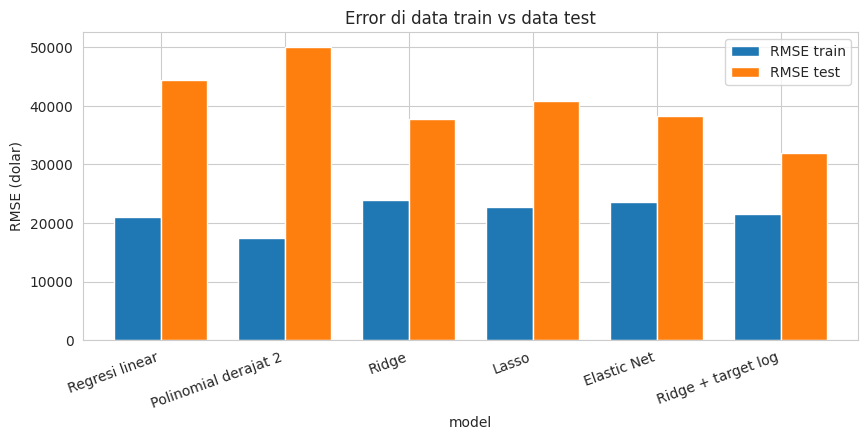

In [10]:
ax = tabel[["RMSE train", "RMSE test"]].plot.bar(figsize=(10, 4), width=0.75)
ax.set_ylabel("RMSE (dolar)")
ax.set_title("Error di data train vs data test")
plt.xticks(rotation=20, ha="right")
plt.show()

**Cara memilih model.** Model dipilih berdasarkan **RMSE cross validation di data train** (kolom `RMSE CV`), bukan RMSE test, supaya data test tetap murni sebagai penilaian akhir. Kolom `RMSE train` dan `RMSE test` dipakai untuk melihat overfitting: model yang error train-nya jauh lebih kecil dari error test-nya cenderung menghafal data latih.

In [11]:
nama_terbaik = tabel["RMSE CV"].idxmin()
print("model terbaik menurut RMSE cross validation:", nama_terbaik)
print("hyperparameter:", param_terpilih[nama_terbaik])

ringkas = tabel.loc[nama_terbaik]
print(f"RMSE CV {ringkas['RMSE CV']:,.0f} | RMSE train {ringkas['RMSE train']:,.0f} | "
      f"RMSE test {ringkas['RMSE test']:,.0f} | R2 test {ringkas['R2 test']:.3f}")

gap = tabel["RMSE test"] - tabel["RMSE train"]
print("\nselisih RMSE test - train tiap model (makin besar = makin overfit):")
print(gap.round(0).to_string())

model terbaik menurut RMSE cross validation: Polinomial derajat 2
hyperparameter: -
RMSE CV 32,349 | RMSE train 17,518 | RMSE test 50,074 | R2 test 0.585

selisih RMSE test - train tiap model (makin besar = makin overfit):
model
Regresi linear          23315.0
Polinomial derajat 2    32556.0
Ridge                   13748.0
Lasso                   18125.0
Elastic Net             14598.0
Ridge + target log      10502.0


Pembacaannya: regresi linear dan polinomial tanpa regularisasi cenderung punya selisih train-test yang lebih besar karena jumlah fiturnya banyak dibanding jumlah data. Model dengan regularisasi (Ridge, Lasso, Elastic Net) menahan koefisien sehingga selisihnya lebih kecil. Tabel di atas menunjukkan mana yang paling baik di data ini, dan model itulah yang paling memenuhi tujuan prediksi.

## 4. Temuan dan Interpretasi

### 4.1 Performa model terbaik di data test

In [12]:
model_terbaik = terlatih[nama_terbaik]
pred = model_terbaik.predict(X_test)

rmse_t = rmse(y_test, pred)
mae_t = mean_absolute_error(y_test, pred)
r2_t = r2_score(y_test, pred)
mape_t = (np.abs(y_test - pred) / y_test).mean() * 100

print(f"Model        : {nama_terbaik}")
print(f"RMSE         : {rmse_t:,.0f} dolar")
print(f"MAE          : {mae_t:,.0f} dolar")
print(f"R2           : {r2_t:.3f}")
print(f"MAPE         : {mape_t:.1f}%")
print(f"RMSE terhadap harga rata-rata: {rmse_t / y_test.mean() * 100:.1f}%")

Model        : Polinomial derajat 2
RMSE         : 50,074 dolar
MAE          : 21,901 dolar
R2           : 0.585
MAPE         : 13.1%
RMSE terhadap harga rata-rata: 27.3%


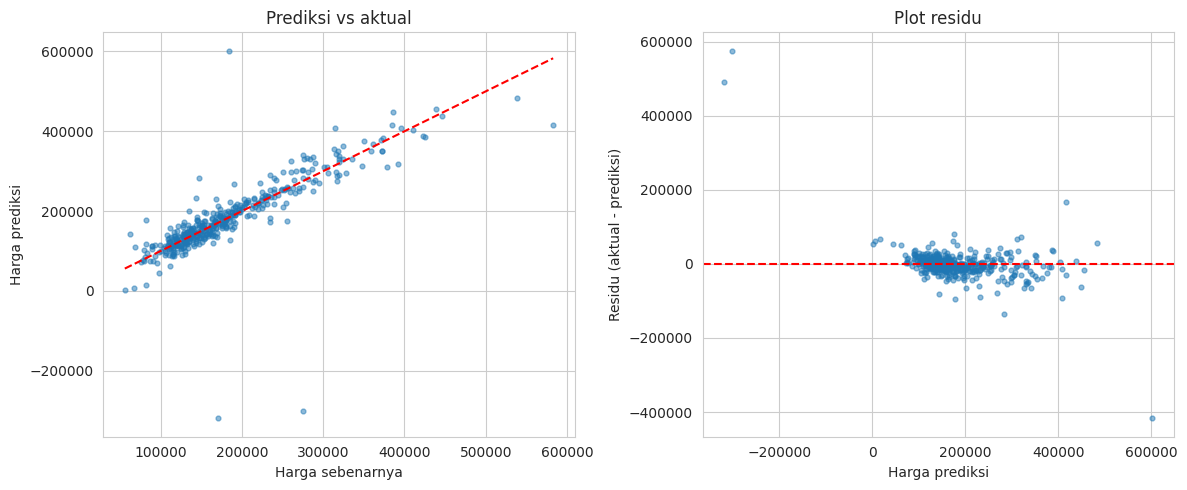

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, pred, s=12, alpha=0.5)
batas = [y_test.min(), y_test.max()]
axes[0].plot(batas, batas, "r--")
axes[0].set(xlabel="Harga sebenarnya", ylabel="Harga prediksi", title="Prediksi vs aktual")

residu = y_test - pred
axes[1].scatter(pred, residu, s=12, alpha=0.5)
axes[1].axhline(0, color="r", ls="--")
axes[1].set(xlabel="Harga prediksi", ylabel="Residu (aktual - prediksi)", title="Plot residu")
plt.tight_layout()
plt.show()

Titik yang dekat garis putus-putus di grafik kiri berarti prediksinya akurat. Di grafik kanan, residu yang tersebar acak di sekitar nol menandakan model tidak punya pola kesalahan yang jelas. Kalau residunya melebar pada harga tinggi, berarti model kurang andal untuk rumah mahal.

### 4.2 Seberapa besar error di tiap kelompok harga

In [14]:
kuartil = pd.qcut(y_test, 4, labels=["Q1 termurah", "Q2", "Q3", "Q4 termahal"])
galat = pd.DataFrame({
    "kuartil": kuartil,
    "MAE (dolar)": (y_test - pred).abs(),
    "error (%)": (y_test - pred).abs() / y_test * 100,
})
per_kuartil = galat.groupby("kuartil", observed=True).mean().round(1)
per_kuartil

,MAE (dolar),error (%)
kuartil,,
Q1 termurah,17812.0,18.1
Q2,15680.3,10.8
Q3,23474.8,13.0
Q4 termahal,30591.9,10.4


In [15]:
terbesar = per_kuartil["MAE (dolar)"].idxmax()
terkecil_persen = per_kuartil["error (%)"].idxmin()
print(f"Error dalam dolar paling besar ada di kelompok: {terbesar}")
print(f"Error dalam persen paling kecil ada di kelompok: {terkecil_persen}")

Error dalam dolar paling besar ada di kelompok: Q4 termahal
Error dalam persen paling kecil ada di kelompok: Q4 termahal


### 4.3 Fitur yang paling berpengaruh

Untuk interpretasi aku pakai model **Lasso** yang sudah dituning. Alasannya bukan karena Lasso pasti paling akurat, tapi karena koefisiennya bisa dibaca langsung dan Lasso otomatis menjadikan fitur yang tidak berguna bernilai nol. Karena semua fitur sudah distandardisasi, koefisien antar fitur bisa dibandingkan: koefisien menunjukkan perubahan harga prediksi (dalam dolar) bila fitur itu naik satu standar deviasi, dengan fitur lain tetap.

koefisien tidak nol: 121 dari 240 fitur


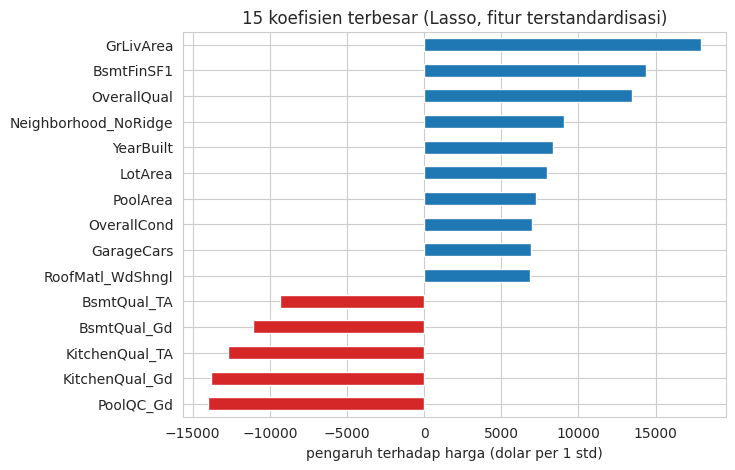

In [16]:
lasso = terlatih["Lasso"]["model"]
koef = pd.Series(lasso.coef_, index=X_train.columns)

print(f"koefisien tidak nol: {np.count_nonzero(koef)} dari {len(koef)} fitur")

teratas = koef.reindex(koef.abs().sort_values(ascending=False).index).head(15)
teratas.sort_values().plot.barh(figsize=(7, 5),
                                color=["tab:red" if v < 0 else "tab:blue" for v in teratas.sort_values()])
plt.title("15 koefisien terbesar (Lasso, fitur terstandardisasi)")
plt.xlabel("pengaruh terhadap harga (dolar per 1 std)")
plt.show()

In [17]:
print("5 fitur pendorong kenaikan harga:")
print(koef.nlargest(5).round(0).to_string())
print()
print("5 fitur pendorong penurunan harga:")
print(koef.nsmallest(5).round(0).to_string())

5 fitur pendorong kenaikan harga:
GrLivArea               17945.0
BsmtFinSF1              14378.0
OverallQual             13480.0
Neighborhood_NoRidge     9054.0
YearBuilt                8317.0

5 fitur pendorong penurunan harga:
PoolQC_Gd        -14018.0
KitchenQual_Gd   -13807.0
KitchenQual_TA   -12687.0
BsmtQual_Gd      -11086.0
BsmtQual_TA       -9346.0


Fitur dengan koefisien positif besar menaikkan harga prediksi, yang negatif besar menurunkannya. Perlu diingat bahwa ini hubungan statistik, bukan sebab-akibat, dan fitur yang saling berkorelasi (misalnya luas bangunan dan jumlah kamar) bisa saling membagi pengaruhnya sehingga koefisien satu fitur menjadi tampak kecil.

### 4.4 Ringkasan temuan

In [18]:
print("RINGKASAN TEMUAN")
print("-" * 60)
print(f"1. Model terbaik berdasarkan cross validation: {nama_terbaik}.")
print(f"2. Pada data test, RMSE-nya {rmse_t:,.0f} dolar "
      f"({rmse_t / y_test.mean() * 100:.1f}% dari harga rata-rata) dan R2 {r2_t:.3f}.")
print(f"3. Rata-rata kesalahan relatif (MAPE) sekitar {mape_t:.1f}%.")
print(f"4. Model regresi linear biasa punya R2 test {tabel.loc['Regresi linear', 'R2 test']:.3f}, "
      f"sedangkan model terbaik {r2_t:.3f}.")
print(f"5. Lasso menyisakan {np.count_nonzero(koef)} fitur aktif dari {len(koef)}.")
print(f"6. Fitur dengan pengaruh positif terbesar: {koef.idxmax()}; "
      f"pengaruh negatif terbesar: {koef.idxmin()}.")

RINGKASAN TEMUAN
------------------------------------------------------------
1. Model terbaik berdasarkan cross validation: Polinomial derajat 2.
2. Pada data test, RMSE-nya 50,074 dolar (27.3% dari harga rata-rata) dan R2 0.585.
3. Rata-rata kesalahan relatif (MAPE) sekitar 13.1%.
4. Model regresi linear biasa punya R2 test 0.674, sedangkan model terbaik 0.585.
5. Lasso menyisakan 121 fitur aktif dari 240.
6. Fitur dengan pengaruh positif terbesar: GrLivArea; pengaruh negatif terbesar: PoolQC_Gd.


## 5. Evaluasi

### Kekurangan model ini

- **Asumsi linear.** Semua model yang dicoba bersifat linear terhadap fiturnya (atau polinomial terbatas). Hubungan harga dengan fitur bisa jauh lebih kompleks, misalnya interaksi antara lokasi dan kualitas bangunan.
- **Error tidak merata.** Seperti terlihat di bagian 4.2, besar error berbeda antar kelompok harga. Rumah termahal sedikit jumlahnya sehingga model kurang belajar darinya.
- **Outlier tidak ditangani.** Dataset ini punya beberapa rumah ekstrem (misalnya luas bangunan sangat besar dengan harga rendah) yang tidak dibuang atau ditangani khusus, dan bisa menarik model.
- **Encoding kategorikal sederhana.** One-hot encoding menambah ratusan kolom, banyak di antaranya jarang berisi nilai 1. Fitur ordinal (misalnya tingkat kualitas) diperlakukan seperti kategori biasa, sehingga urutannya hilang.
- **Cakupan data terbatas.** Data hanya dari satu kota dan periode tertentu, jadi model belum tentu berlaku di kota lain atau saat kondisi pasar berubah.
- **Hubungan, bukan sebab-akibat.** Koefisien menggambarkan asosiasi statistik. Menaikkan nilai suatu fitur pada rumah tertentu belum tentu menaikkan harganya sebesar koefisien itu.

## Kesimpulan

Dari enam model linear yang dibandingkan, model terbaik dipilih lewat cross validation di data train dan dinilai sekali di data test. Regularisasi membantu mengendalikan overfitting yang muncul saat fitur one-hot sangat banyak, dan Lasso memberi gambaran fitur mana yang paling berpengaruh terhadap harga. Hasil prediksinya cukup untuk perkiraan kasar, tetapi masih punya keterbatasan yang bisa diperbaiki dengan data tambahan dan model non-linear.